# Modelo Predictivo de Riesgo Académico — Comparación de Algoritmos

Este notebook entrena y compara cinco algoritmos de clasificación supervisada
sobre `dataset.csv` (generado por `GeneradorBD.ipynb`) para predecir el
riesgo académico de un estudiante:

1. Regresión Logística
2. Árbol de Decisión
3. Random Forest (Bosques Aleatorios)
4. Support Vector Machine (SVM)
5. Red Neuronal Profunda (Deep Neural Network)

**Nota importante sobre los datos:** `dataset.csv` ya no incluye la columna
objetivo (`riesgo_academico_confirmado`) porque se eliminó del archivo
exportado en `GeneradorBD.ipynb`. Para poder entrenar y **evaluar**
algoritmos supervisados es indispensable contar con un desenlace conocido,
así que en este notebook se reconstruye una etiqueta histórica de referencia
aplicando la misma regla de riesgo definida originalmente en el diseño del
dataset (combinación logística de los factores de riesgo). Esto reproduce
una situación real de trabajo: se entrena con datos históricos donde el
desenlace ya se conoce (aprobó/desertó), y el modelo resultante se usa
después para estudiantes cuyo desenlace todavía no se sabe.

Al final, el modelo con mejor desempeño se reentrena con todos los registros
y se usa para generar las predicciones que se exportan en
`riesgo_academico.csv`.


In [1]:
# --- 1. Librerías ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Preprocesamiento y partición de datos
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Los cinco algoritmos a comparar
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier   # Red neuronal (DNN) vía scikit-learn

# Métricas de evaluación
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
)

SEED = 42
np.random.seed(SEED)


## 2. Carga del dataset

Se carga `dataset.csv`, generado previamente, que contiene únicamente las
variables predictoras (sin la etiqueta de riesgo).

In [2]:
# --- 2. Carga de datos ---
ruta_dataset = Path.cwd() / "dataset.csv"
df = pd.read_csv(ruta_dataset)

print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
df.head()


Filas: 7508 | Columnas: 13


,id_estudiante,id_curso,fecha_corte,carga_academica_actual,calificacion_historica_promedio,tendencia_calificaciones,tasa_acierto_primer_intento,duracion_intento_minutos,indice_friccion_cognitiva,dias_inactividad_consecutivos,tasa_entregas_tardias,nivel_interaccion_social,tasa_visualizacion_materiales
0,EST-0001,CUR-007,2026-04-06,5,11.32,-1.109,0.584,15.7,5.04,8,0.525,0.472,0.698
1,EST-0001,CUR-007,2026-04-27,5,9.94,-1.109,0.256,8.1,1.29,8,0.772,0.426,0.341
2,EST-0001,CUR-007,2026-05-18,5,10.97,-1.109,0.578,11.1,2.66,9,0.835,0.697,0.282
3,EST-0001,CUR-007,2026-06-08,5,7.28,-1.109,0.639,2.9,1.64,8,0.681,0.484,0.539
4,EST-0001,CUR-008,2026-04-06,5,10.14,-0.730,0.702,5.9,2.22,5,0.558,0.461,0.521


## 3. Reconstrucción de la etiqueta histórica de riesgo

Se recalcula el riesgo aplicando la misma lógica usada al diseñar el
dataset: estandarizar los factores de riesgo, combinarlos con los mismos
pesos (aumentan el riesgo: inactividad, entregas tardías, fricción
cognitiva; lo disminuyen: calificación, tendencia, acierto, interacción
social, visualización de materiales), pasar el resultado por una función
logística y muestrear un resultado binario. Esta etiqueta (`riesgo_historico`)
se usa **solo para entrenar y evaluar los modelos**; no se calcula a partir
de información que no esté disponible en `dataset.csv`.

In [3]:
# --- 3. Reconstrucción de la variable objetivo histórica ---
def estandarizar(serie):
    return (serie - serie.mean()) / serie.std()

z_riesgo = (
      1.4 * estandarizar(df["dias_inactividad_consecutivos"])
    + 1.1 * estandarizar(df["tasa_entregas_tardias"])
    + 0.6 * estandarizar(df["indice_friccion_cognitiva"])
    - 1.3 * estandarizar(df["calificacion_historica_promedio"])
    - 0.9 * estandarizar(df["tendencia_calificaciones"])
    - 0.7 * estandarizar(df["tasa_acierto_primer_intento"])
    - 0.5 * estandarizar(df["nivel_interaccion_social"])
    - 0.4 * estandarizar(df["tasa_visualizacion_materiales"])
    - 1.8
    + np.random.normal(0, 0.6, size=len(df))
)
probabilidad_riesgo = 1 / (1 + np.exp(-z_riesgo))
df["riesgo_historico"] = np.random.binomial(1, probabilidad_riesgo)

print("Distribución de la etiqueta histórica (usada para entrenar):")
print(df["riesgo_historico"].value_counts(normalize=True).round(3))


Distribución de la etiqueta histórica (usada para entrenar):
riesgo_historico
0    0.679
1    0.321
Name: proportion, dtype: float64


## 4. Selección de variables predictoras

Se excluyen los identificadores (`id_estudiante`, `id_curso`, `fecha_corte`)
porque no son variables generalizables para un estudiante nuevo: son claves
de identificación, no características de comportamiento o rendimiento.
Todas las demás columnas numéricas se usan como *features*.

In [4]:
# --- 4. Definición de X (features) e y (target) ---
columnas_excluidas = ["id_estudiante", "id_curso", "fecha_corte", "riesgo_historico"]
feature_cols = [c for c in df.columns if c not in columnas_excluidas]

X = df[feature_cols].copy()
y = df["riesgo_historico"].copy()

print("Variables predictoras utilizadas:")
print(feature_cols)


Variables predictoras utilizadas:
['carga_academica_actual', 'calificacion_historica_promedio', 'tendencia_calificaciones', 'tasa_acierto_primer_intento', 'duracion_intento_minutos', 'indice_friccion_cognitiva', 'dias_inactividad_consecutivos', 'tasa_entregas_tardias', 'nivel_interaccion_social', 'tasa_visualizacion_materiales']


## 5. Partición en entrenamiento y prueba

Se separa el 75% de los datos para entrenar y el 25% para evaluar, usando
muestreo estratificado (`stratify=y`) para que la proporción de riesgo se
mantenga similar en ambos subconjuntos, dado que la clase está algo
desbalanceada.

In [5]:
# --- 5. Train / test split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)
print(f"Entrenamiento: {X_train.shape[0]} filas | Prueba: {X_test.shape[0]} filas")


Entrenamiento: 5631 filas | Prueba: 1877 filas


## 6. Escalado de variables

La Regresión Logística, el SVM y la Red Neuronal son sensibles a la escala
de las variables (funcionan mejor cuando todas las variables están en un
rango comparable). El `StandardScaler` se **ajusta solo con el conjunto de
entrenamiento** y luego se aplica igual a entrenamiento y prueba, para no
filtrar información del conjunto de prueba hacia el proceso de ajuste
(evitar *data leakage*). Los modelos basados en árboles (Decisión, Random
Forest) no lo necesitan, pero usar los mismos datos escalados para todos
simplifica el código sin afectar su desempeño.

In [6]:
# --- 6. Escalado ---
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)


## 7. Definición de los cinco algoritmos

Cada modelo se define con hiperparámetros razonables para un dataset de este
tamaño, sin optimización exhaustiva (eso sería un siguiente paso con
`GridSearchCV`):

- **Regresión Logística**: modelo lineal, referencia base interpretable.
- **Árbol de Decisión**: captura relaciones no lineales, fácil de
  interpretar; se limita la profundidad para evitar sobreajuste.
- **Random Forest**: conjunto de árboles, generalmente más robusto y preciso
  que un árbol individual.
- **SVM**: con kernel RBF para capturar fronteras de decisión no lineales;
  `probability=True` habilita `predict_proba` para poder calcular ROC-AUC.
- **Red Neuronal Profunda (MLP)**: perceptrón multicapa con tres capas
  ocultas (64, 32 y 16 neuronas), como aproximación de una DNN dentro de
  scikit-learn.

In [7]:
# --- 7. Modelos a comparar ---
modelos = {
    "Regresión Logística": LogisticRegression(max_iter=1000, random_state=SEED),
    "Árbol de Decisión": DecisionTreeClassifier(max_depth=6, random_state=SEED),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=10, random_state=SEED, n_jobs=-1
    ),
    "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=SEED),
    "Red Neuronal (DNN)": MLPClassifier(
        hidden_layer_sizes=(64, 32, 16), max_iter=600, random_state=SEED
    ),
}


## 8. Entrenamiento y evaluación

Se entrena cada modelo con los datos escalados de entrenamiento, se predice
sobre el conjunto de prueba y se calculan cinco métricas: exactitud
(*accuracy*), precisión, *recall*, F1-score y AUC-ROC. Se guardan también las
probabilidades predichas y las predicciones binarias de cada modelo, porque
se necesitan más adelante para las curvas ROC y las matrices de confusión.

In [8]:
# --- 8. Entrenamiento, predicción y cálculo de métricas ---
resultados = []
predicciones = {}      # etiquetas 0/1 predichas por cada modelo (conjunto de prueba)
probabilidades = {}    # probabilidad de clase 1 por cada modelo (conjunto de prueba)

for nombre, modelo in modelos.items():
    modelo.fit(X_train_esc, y_train)

    y_pred = modelo.predict(X_test_esc)
    y_proba = modelo.predict_proba(X_test_esc)[:, 1]

    predicciones[nombre] = y_pred
    probabilidades[nombre] = y_proba

    resultados.append({
        "modelo": nombre,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1_score": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba),
    })

    print(f"--- {nombre} ---")
    print(classification_report(y_test, y_pred, target_names=["Sin riesgo", "Riesgo"]))

comparativa = pd.DataFrame(resultados).set_index("modelo")


--- Regresión Logística ---
              precision    recall  f1-score   support

  Sin riesgo       0.90      0.92      0.91      1275
      Riesgo       0.82      0.78      0.80       602

    accuracy                           0.88      1877
   macro avg       0.86      0.85      0.86      1877
weighted avg       0.87      0.88      0.87      1877

--- Árbol de Decisión ---
              precision    recall  f1-score   support

  Sin riesgo       0.85      0.90      0.87      1275
      Riesgo       0.76      0.66      0.71       602

    accuracy                           0.82      1877
   macro avg       0.80      0.78      0.79      1877
weighted avg       0.82      0.82      0.82      1877

--- Random Forest ---
              precision    recall  f1-score   support

  Sin riesgo       0.89      0.92      0.91      1275
      Riesgo       0.83      0.75      0.79       602

    accuracy                           0.87      1877
   macro avg       0.86      0.84      0.85      187

C:\Users\renzo\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


--- SVM (RBF) ---
              precision    recall  f1-score   support

  Sin riesgo       0.89      0.93      0.91      1275
      Riesgo       0.84      0.76      0.80       602

    accuracy                           0.87      1877
   macro avg       0.86      0.84      0.85      1877
weighted avg       0.87      0.87      0.87      1877

--- Red Neuronal (DNN) ---
              precision    recall  f1-score   support

  Sin riesgo       0.87      0.87      0.87      1275
      Riesgo       0.73      0.73      0.73       602

    accuracy                           0.83      1877
   macro avg       0.80      0.80      0.80      1877
weighted avg       0.83      0.83      0.83      1877



--- Random Forest ---
              precision    recall  f1-score   support

  Sin riesgo       0.88      0.94      0.91      1266
      Riesgo       0.85      0.73      0.78       611

    accuracy                           0.87      1877
   macro avg       0.86      0.83      0.85      1877
weighted avg       0.87      0.87      0.87      1877



--- SVM (RBF) ---
              precision    recall  f1-score   support

  Sin riesgo       0.88      0.95      0.91      1266
      Riesgo       0.87      0.74      0.80       611

    accuracy                           0.88      1877
   macro avg       0.88      0.84      0.86      1877
weighted avg       0.88      0.88      0.88      1877



--- Red Neuronal (DNN) ---
              precision    recall  f1-score   support

  Sin riesgo       0.86      0.90      0.88      1266
      Riesgo       0.77      0.70      0.73       611

    accuracy                           0.83      1877
   macro avg       0.81      0.80      0.81      1877
weighted avg       0.83      0.83      0.83      1877



## 9. Tabla comparativa de métricas

Se ordena de mayor a menor F1-score, la métrica más equilibrada cuando las
clases no están perfectamente balanceadas (como es el caso aquí).

In [14]:
# --- 9. Tabla comparativa ---
comparativa_ordenada = comparativa.sort_values("f1_score", ascending=False).round(4)
comparativa_ordenada


,accuracy,precision,recall,f1_score,roc_auc
modelo,,,,,
Regresión Logística,0.8759,0.8243,0.7791,0.8010,0.9431
SVM (RBF),0.8748,0.8355,0.7591,0.7955,0.9325
Random Forest,0.8700,0.8255,0.7542,0.7882,0.9362
Red Neuronal (DNN),0.8274,0.7301,0.7326,0.7313,0.8966
Árbol de Decisión,0.8247,0.7590,0.6645,0.7086,0.8910


## 10. Visualización 1 — Comparación de métricas por modelo

Gráfico de barras agrupadas que muestra, para cada modelo, sus cuatro
métricas principales lado a lado.

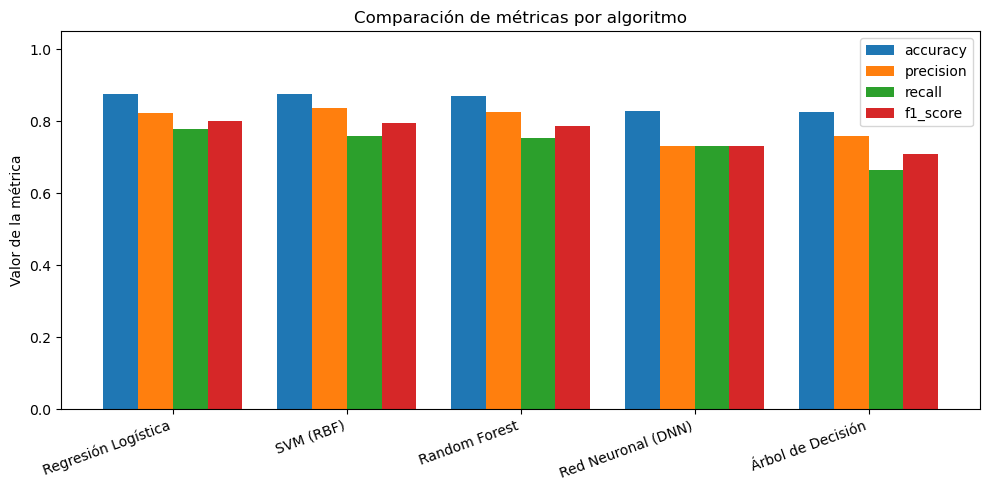

In [15]:
# --- 10. Gráfico de barras comparativo ---
metricas_a_graficar = ["accuracy", "precision", "recall", "f1_score"]
x = np.arange(len(comparativa_ordenada))
ancho = 0.2

fig, ax = plt.subplots(figsize=(10, 5))
for i, metrica in enumerate(metricas_a_graficar):
    ax.bar(x + i * ancho, comparativa_ordenada[metrica], width=ancho, label=metrica)

ax.set_xticks(x + ancho * 1.5)
ax.set_xticklabels(comparativa_ordenada.index, rotation=20, ha="right")
ax.set_ylabel("Valor de la métrica")
ax.set_title("Comparación de métricas por algoritmo")
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.show()


## 11. Visualización 2 — Curvas ROC

Se superponen las curvas ROC de los cinco modelos sobre el conjunto de
prueba. Cuanto más se acerque una curva a la esquina superior izquierda,
mejor distingue el modelo entre estudiantes en riesgo y sin riesgo.

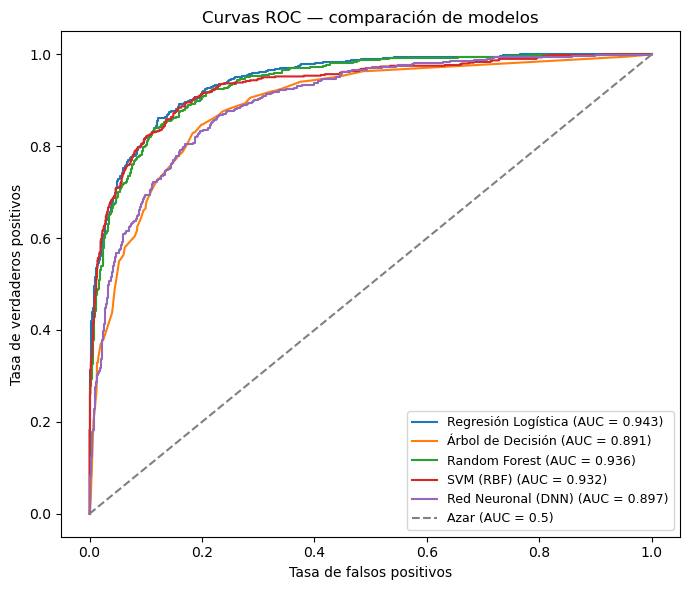

In [13]:
# --- 11. Curvas ROC ---
fig, ax = plt.subplots(figsize=(7, 6))
for nombre in modelos:
    fpr, tpr, _ = roc_curve(y_test, probabilidades[nombre])
    auc = comparativa.loc[nombre, "roc_auc"]
    ax.plot(fpr, tpr, label=f"{nombre} (AUC = {auc:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC = 0.5)")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Curvas ROC — comparación de modelos")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()


## 12. Visualización 3 — Matrices de confusión

Una cuadrícula con la matriz de confusión de cada modelo, para observar en
detalle cuántos falsos positivos y falsos negativos comete cada uno (algo
que el F1-score resume en un solo número, pero que conviene revisar
directamente).

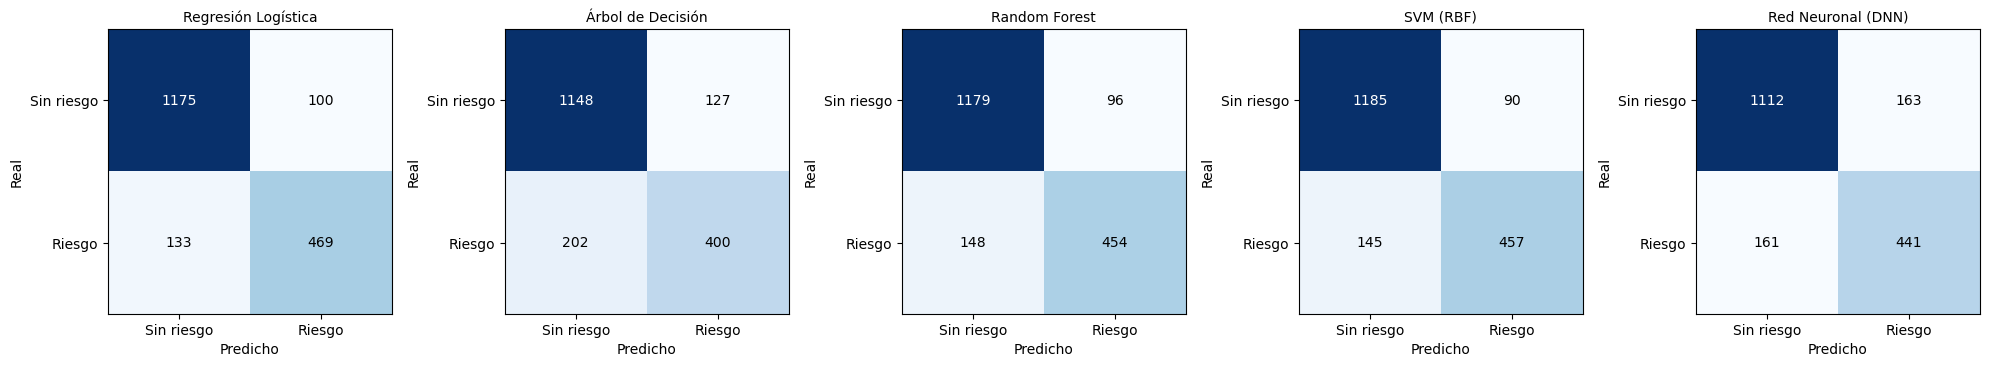

In [11]:
# --- 12. Matrices de confusión ---
fig, axes = plt.subplots(1, len(modelos), figsize=(4 * len(modelos), 4))
for ax, nombre in zip(axes, modelos):
    matriz = confusion_matrix(y_test, predicciones[nombre])
    im = ax.imshow(matriz, cmap="Blues")
    ax.set_title(nombre, fontsize=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Sin riesgo", "Riesgo"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Sin riesgo", "Riesgo"])
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, matriz[i, j], ha="center", va="center",
                     color="white" if matriz[i, j] > matriz.max() / 2 else "black")

plt.tight_layout()
plt.show()


## 13. Visualización 4 — Importancia de variables (Random Forest)

El Random Forest permite extraer qué tan importante fue cada variable para
sus decisiones. Es útil para validar si el modelo se apoya en las variables
que, conceptualmente, deberían importar más (inactividad, calificación,
tendencia).

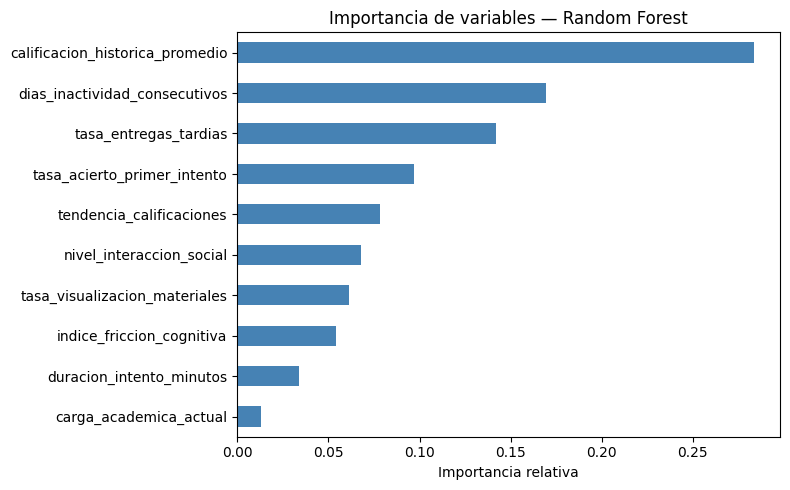

In [13]:
# --- 13. Importancia de variables ---
importancias = pd.Series(
    modelos["Random Forest"].feature_importances_, index=feature_cols
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
importancias.plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Importancia de variables — Random Forest")
ax.set_xlabel("Importancia relativa")
plt.tight_layout()
plt.show()


## 14. Selección del mejor modelo

El mejor modelo se elige de forma programática (no a simple vista) como el
que obtiene el mayor F1-score en el conjunto de prueba, por ser la métrica
que mejor equilibra precisión y recall ante clases desbalanceadas.

In [14]:
# --- 14. Selección automática del mejor modelo ---
mejor_modelo_nombre = comparativa["f1_score"].idxmax()
mejor_modelo = modelos[mejor_modelo_nombre]

print(f"Mejor modelo según F1-score: {mejor_modelo_nombre}")
print(comparativa.loc[mejor_modelo_nombre].round(4))


Mejor modelo según F1-score: Regresión Logística
accuracy     0.8860
precision    0.8577
recall       0.7791
f1_score     0.8165
roc_auc      0.9501
Name: Regresión Logística, dtype: float64


## 15. Reentrenamiento final y generación de predicciones

Una vez identificado el mejor algoritmo, se reentrena usando **todos** los
registros disponibles (entrenamiento + prueba), aprovechando toda la
información antes de aplicarlo sobre el dataset completo. Después se predice
el riesgo (etiqueta y probabilidad) para cada fila del dataset original y se
exporta el resultado.

In [15]:
# --- 15. Reentrenamiento con todos los datos ---
X_completo_esc = scaler.fit_transform(X)   # se reajusta el escalador con todos los datos
mejor_modelo.fit(X_completo_esc, y)

dataset_final = df[feature_cols + ["id_estudiante", "id_curso", "fecha_corte"]].copy()
dataset_final["probabilidad_riesgo"] = mejor_modelo.predict_proba(X_completo_esc)[:, 1].round(4)
dataset_final["riesgo_academico_confirmado"] = mejor_modelo.predict(X_completo_esc)

# Se reordena para que los identificadores queden primero, como en dataset.csv.
orden_columnas = (
    ["id_estudiante", "id_curso", "fecha_corte"]
    + feature_cols
    + ["probabilidad_riesgo", "riesgo_academico_confirmado"]
)
dataset_final = dataset_final[orden_columnas]
dataset_final.head()


,id_estudiante,id_curso,fecha_corte,carga_academica_actual,calificacion_historica_promedio,tendencia_calificaciones,tasa_acierto_primer_intento,duracion_intento_minutos,indice_friccion_cognitiva,dias_inactividad_consecutivos,tasa_entregas_tardias,nivel_interaccion_social,tasa_visualizacion_materiales,probabilidad_riesgo,riesgo_academico_confirmado
0,EST-0001,CUR-007,2026-04-06,5,11.32,-1.109,0.584,1.1,3.07,5,0.231,0.781,0.441,0.0934,0
1,EST-0001,CUR-007,2026-04-27,5,9.94,-1.109,0.256,11.2,1.72,4,0.646,0.578,0.114,0.8204,1
2,EST-0001,CUR-007,2026-05-18,5,10.97,-1.109,0.578,24.4,1.47,6,0.733,0.364,0.465,0.7670,1
3,EST-0001,CUR-007,2026-06-08,5,7.28,-1.109,0.639,3.1,3.09,10,0.675,0.512,0.535,0.9772,1
4,EST-0001,CUR-008,2026-04-06,5,10.14,-0.730,0.702,4.2,2.29,8,0.573,0.363,0.538,0.7001,1


## 16. Exportación de `riesgo_academico.csv`

Se guarda en la misma carpeta que `dataset.csv` y `GeneradorBD.ipynb`.
La columna `riesgo_academico_confirmado` contiene la predicción del modelo
con mejor desempeño (impreso en la celda siguiente), no una observación
real; por eso se acompaña de `probabilidad_riesgo`, que permite matizar qué
tan segura fue cada predicción.

In [16]:
# --- 16. Exportación final ---
ruta_salida = Path.cwd() / "riesgo_academico.csv"
dataset_final.to_csv(ruta_salida, index=False, encoding="utf-8-sig")

print(f"Modelo utilizado para las predicciones finales: {mejor_modelo_nombre}")
print(f"Archivo exportado en: {ruta_salida.resolve()}")
print("Distribución de riesgo predicho:")
print(dataset_final["riesgo_academico_confirmado"].value_counts(normalize=True).round(3))


Modelo utilizado para las predicciones finales: Regresión Logística
Archivo exportado en: /home/claude/MobileLearning/riesgo_academico.csv
Distribución de riesgo predicho:
riesgo_academico_confirmado
0    0.698
1    0.302
Name: proportion, dtype: float64
